# Clasificación de Exoplanetas - Misión Kepler (NASA)

**Actividad Sumativa - Unidad 4: Inteligencia Artificial**

---

## 1. Contexto del problema y justificación

El telescopio espacial **Kepler** (2009-2018) detectó miles de señales de tránsito: pequeñas caídas periódicas en el brillo de una estrella cuando un planeta pasa frente a ella. Cada señal se cataloga como un *Kepler Object of Interest* (KOI).

**Problema real**: de los 9,564 KOIs del catálogo, solo una fracción son planetas confirmados; el resto son **falsos positivos** (binarias eclipsantes, contaminación de estrellas vecinas, ruido instrumental) o siguen como **candidatos** sin resolver. Confirmar un candidato requiere tiempo de telescopios terrestres de gran apertura, un recurso escaso y costoso.

**Objetivo**: entrenar un clasificador que estime la probabilidad de que un KOI sea un planeta real (`CONFIRMED`) frente a un `FALSE POSITIVE`, usando únicamente parámetros físicos de la señal, del planeta y de la estrella, para **priorizar** qué candidatos observar primero.

**Dataset**: tabla *Kepler Objects of Interest — cumulative* del NASA Exoplanet Archive (misma estructura de 50 columnas que el dataset de Kaggle `nasa/kepler-exoplanet-search-results`), descargada vía la API TAP pública del archivo.

**Tipo de problema**: **clasificación binaria supervisada**. Es supervisado porque existe una etiqueta (`koi_disposition`) asignada por expertos tras el seguimiento observacional. La clase `CANDIDATE` se excluye del entrenamiento (no tiene etiqueta definitiva) y se usa al final para hacer predicciones operativas.

## 2. Imports y configuración

In [1]:
import json
import warnings
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Stack de machine learning
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, balanced_accuracy_score,
                             accuracy_score, precision_score, recall_score, f1_score)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import sklearn, xgboost, lightgbm

warnings.filterwarnings('ignore', category=UserWarning)

# Semilla global para reproducibilidad
SEED = 42
np.random.seed(SEED)

# Carpeta donde se guardan las figuras que usa el informe técnico
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"xgboost {xgboost.__version__} | lightgbm {lightgbm.__version__}")

pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0


## 3. Carga y exploración inicial del dataset

In [2]:
# Ruta al dataset. Si no existe localmente se descarga de la API TAP del NASA Exoplanet Archive.
data_path = Path('cumulative.csv')
if not data_path.exists():
    cols = ("kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,"
            "koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,"
            "koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,"
            "koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,"
            "koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,"
            "koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,"
            "koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag")
    url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?format=csv&query="
           + f"select+{cols}+from+cumulative+order+by+kepoi_name")
    tmp = pd.read_csv(url)
    tmp.insert(0, 'rowid', range(1, len(tmp) + 1))
    tmp.to_csv(data_path, index=False)

df_raw = pd.read_csv(data_path)
print(f"Shape: {df_raw.shape}")
print(f"Columnas ({len(df_raw.columns)}): {list(df_raw.columns)}")

Shape: (9564, 50)
Columnas (50): ['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']


In [3]:
df_raw.head(3).T

,0,1,2
rowid,1,2,3
kepid,11446443,10666592,10748390
kepoi_name,K00001.01,K00002.01,K00003.01
kepler_name,Kepler-1 b,Kepler-2 b,Kepler-3 b
koi_disposition,CONFIRMED,CONFIRMED,CONFIRMED
koi_pdisposition,CANDIDATE,CANDIDATE,CANDIDATE
koi_score,0.811,1.0,0.913
koi_fpflag_nt,0,0,0
koi_fpflag_ss,0,1,0
koi_fpflag_co,0,0,0


In [4]:
# Distribución de la variable objetivo original (3 clases)
print(df_raw['koi_disposition'].value_counts())
print(df_raw['koi_disposition'].value_counts(normalize=True).round(4))

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64
koi_disposition
FALSE POSITIVE    0.5060
CONFIRMED         0.2873
CANDIDATE         0.2067
Name: proportion, dtype: float64


In [5]:
# Porcentaje de nulos por columna (solo columnas con nulos)
null_pct = (df_raw.isnull().mean() * 100).sort_values(ascending=False)
null_pct[null_pct > 0].head(15)

koi_teq_err2        100.000000
koi_teq_err1        100.000000
kepler_name          71.267252
koi_score            15.788373
koi_steff_err2        5.050188
koi_srad_err2         4.893350
koi_srad_err1         4.893350
koi_steff_err1        4.893350
koi_slogg_err2        4.893350
koi_slogg_err1        4.893350
koi_time0bk_err1      4.746968
koi_time0bk_err2      4.746968
koi_period_err1       4.746968
koi_period_err2       4.746968
koi_impact_err2       4.746968
dtype: float64

## 4. Limpieza y control de *data leakage*

Decisiones:
- **Filtrado**: solo `CONFIRMED` y `FALSE POSITIVE` (etiquetas definitivas).
- **Codificación del objetivo**: `1 = CONFIRMED` (clase positiva = planeta real), `0 = FALSE POSITIVE`. Así *precision*, *recall* y PR-AUC se refieren directamente a la recuperación de planetas.
- **Leakage explícito**: `koi_pdisposition`, `koi_score` y las banderas `koi_fpflag_*` son salidas del proceso de vetting de Kepler, que se construye con la misma información que define la etiqueta.
- **Leakage sutil, columnas de incertidumbre (`*_err1`, `*_err2`)**: cuando un KOI se confirma, sus parámetros (sobre todo los estelares) suelen refinarse con observaciones de seguimiento, lo que cambia el tamaño de sus barras de error. Las incertidumbres codifican entonces en parte *el proceso de confirmación* y no la física de la señal, y un candidato nuevo todavía no las tiene refinadas. Se excluyen del modelo final; la evidencia está en la celda siguiente y su efecto se cuantifica en la sección 10.
- **Identificadores** (`rowid`, `kepid`, `kepoi_name`, `kepler_name`) y columnas con más de 50 % de nulos.

In [6]:
df = df_raw[df_raw['koi_disposition'].isin(['CONFIRMED', 'FALSE POSITIVE'])].copy()
df['target'] = (df['koi_disposition'] == 'CONFIRMED').astype(int)   # 1 = CONFIRMED, 0 = FALSE POSITIVE
print(f"Muestras binarias: {len(df)}")
print(df['target'].value_counts().rename({1: 'CONFIRMED (1)', 0: 'FALSE POSITIVE (0)'}))

# Evidencia del leakage en las barras de error: incertidumbre de Teff mucho menor en los confirmados
print("\nkoi_steff_err1 por clase (K):")
print(df.groupby('koi_disposition')['koi_steff_err1'].describe()[['25%', '50%', '75%']])

Muestras binarias: 7587
target
FALSE POSITIVE (0)    4839
CONFIRMED (1)         2748
Name: count, dtype: int64

koi_steff_err1 por clase (K):
                   25%    50%    75%
koi_disposition                     
CONFIRMED         82.0  108.0  156.0
FALSE POSITIVE   152.0  165.0  182.0


In [7]:
id_cols = ['rowid', 'kepid', 'kepoi_name', 'kepler_name']
target_cols = ['koi_disposition', 'koi_pdisposition']
leak_cols = ['koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec']
err_cols_all = [c for c in df.columns if c.endswith(('_err1', '_err2'))]
high_null = [c for c in null_pct[null_pct > 50].index if c not in id_cols]
err_cols = [c for c in err_cols_all if c not in high_null]          # columnas _err utilizables (experimento)

cols_to_drop = sorted(set(id_cols + target_cols + leak_cols + high_null + err_cols_all) & set(df.columns))
df_clean = df.drop(columns=cols_to_drop)
print(f"Columnas eliminadas ({len(cols_to_drop)}): {cols_to_drop}")
print(f"  de ellas, columnas _err: {len(err_cols_all)} | con >50% nulos: {high_null}")
print(f"Shape final (incluye target): {df_clean.shape}")

Columnas eliminadas (33): ['kepid', 'kepler_name', 'kepoi_name', 'koi_depth_err1', 'koi_depth_err2', 'koi_disposition', 'koi_duration_err1', 'koi_duration_err2', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_impact_err1', 'koi_impact_err2', 'koi_insol_err1', 'koi_insol_err2', 'koi_pdisposition', 'koi_period_err1', 'koi_period_err2', 'koi_prad_err1', 'koi_prad_err2', 'koi_score', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad_err1', 'koi_srad_err2', 'koi_steff_err1', 'koi_steff_err2', 'koi_teq_err1', 'koi_teq_err2', 'koi_time0bk_err1', 'koi_time0bk_err2', 'rowid']
  de ellas, columnas _err: 22 | con >50% nulos: ['koi_teq_err2', 'koi_teq_err1']
Shape final (incluye target): (7587, 18)


In [8]:
X = df_clean.drop(columns=['target'])
y = df_clean['target']

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numéricas ({len(numeric_cols)}): {numeric_cols}")
print(f"Categóricas ({len(categorical_cols)}): {categorical_cols}")

Numéricas (16): ['koi_period', 'koi_time0bk', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_insol', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_steff', 'koi_slogg', 'koi_srad', 'ra', 'dec', 'koi_kepmag']
Categóricas (1): ['koi_tce_delivname']


In [9]:
# Numéricas: imputación por mediana (robusta a outliers) + estandarización
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
# Categóricas: imputación por moda + one-hot
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

def make_preprocessor(num_cols):
    return ColumnTransformer(transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, categorical_cols),
    ], remainder='drop')

preprocessor = make_preprocessor(numeric_cols)

## 5. División estratificada y comparación de modelos

El 20 % de los datos se reserva como *test hold-out*. **Toda decisión** (algoritmo, hiperparámetros y umbral de decisión) se toma solo con validación cruzada estratificada de 5 *folds* sobre el 80 % de entrenamiento; el test se usa únicamente para medir. El preprocesamiento va **dentro** del `Pipeline` para que la imputación, el escalado y la selección de variables se ajusten solo con los datos de entrenamiento de cada *fold*.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Train [FP, CONF]: {np.bincount(y_train)} | Test [FP, CONF]: {np.bincount(y_test)}")

Train: (6069, 17) | Test: (1518, 17)
Train [FP, CONF]: [3871 2198] | Test [FP, CONF]: [968 550]


In [11]:
# Información mutua con semilla fija (por defecto es estocástica)
mi_score = partial(mutual_info_classif, random_state=SEED)

def make_pipeline(model, k='all', pre=None):
    # Preprocesamiento -> selección de k variables por información mutua -> modelo
    return Pipeline([
        ('preprocessor', clone(pre if pre is not None else preprocessor)),
        ('select', SelectKBest(mi_score, k=k)),
        ('model', model),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
spw = (y_train == 0).sum() / (y_train == 1).sum()   # peso para balancear la clase minoritaria en XGBoost

models = {
    'LogisticRegression': LogisticRegression(max_iter=5000, class_weight='balanced', random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=300, scale_pos_weight=spw, random_state=SEED, n_jobs=-1, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1),
}

In [12]:
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:22s} ROC-AUC CV: {scores.mean():.4f} ± {scores.std():.4f}")

cv_table = pd.DataFrame({'mean': {k: v.mean() for k, v in cv_results.items()},
                         'std': {k: v.std() for k, v in cv_results.items()}}).sort_values('mean', ascending=False)
cv_table

LogisticRegression     ROC-AUC CV: 0.9303 ± 0.0046


RandomForest           ROC-AUC CV: 0.9757 ± 0.0038


HistGradientBoosting   ROC-AUC CV: 0.9794 ± 0.0035


XGBoost                ROC-AUC CV: 0.9801 ± 0.0033


LightGBM               ROC-AUC CV: 0.9803 ± 0.0029


,mean,std
LightGBM,0.980329,0.002923
XGBoost,0.980065,0.003274
HistGradientBoosting,0.979448,0.003452
RandomForest,0.975712,0.003846
LogisticRegression,0.930274,0.004635


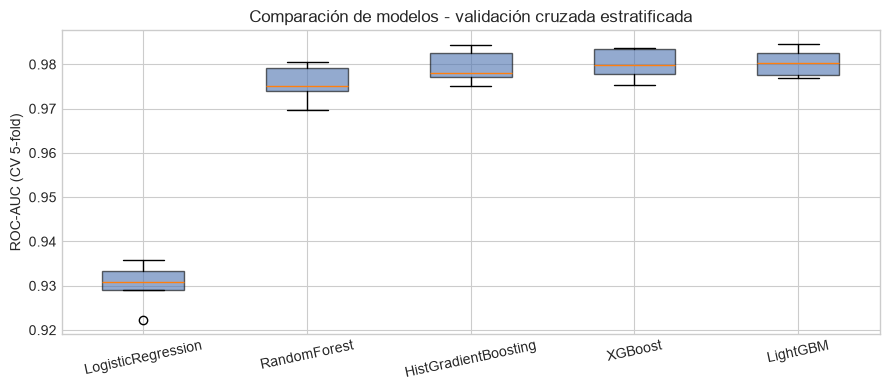

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([cv_results[m] for m in models], tick_labels=list(models), patch_artist=True,
           boxprops=dict(facecolor='#4c72b0', alpha=0.6))
ax.set_ylabel('ROC-AUC (CV 5-fold)')
ax.set_title('Comparación de modelos - validación cruzada estratificada')
plt.xticks(rotation=12)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_cv_models.png', dpi=150)
plt.show()

### Justificación de la elección del algoritmo

**Gradient boosting de árboles (XGBoost / LightGBM)** es la familia más adecuada para este problema:

*Fortalezas*
- Datos **tabulares heterogéneos** (períodos de horas a cientos de días, profundidades de 10 a 10⁵ ppm): los árboles son invariantes a transformaciones monótonas y no requieren supuestos de linealidad.
- Capturan **interacciones no lineales** físicamente relevantes (p. ej. profundidad × radio estelar → radio planetario; un "planeta" de radio > 15 R⊕ suele ser una binaria eclipsante).
- **Regularización** explícita (profundidad máxima / hojas, *learning rate*, *subsample*) para controlar el sobreajuste con ~6,000 muestras.
- Manejo del desbalance mediante `scale_pos_weight` / `class_weight` y entregan **importancias** interpretables.

*Limitaciones*
- Probabilidades no necesariamente calibradas.
- Más hiperparámetros que un modelo lineal y menor interpretabilidad global que una regresión logística.
- No pueden extrapolar fuera del rango de los datos de entrenamiento (relevante al transferir a otra misión como TESS).

La regresión logística sirve como *baseline* lineal y Random Forest como *ensemble* de *bagging* de referencia.

## 6. Optimización de hiperparámetros (GridSearchCV)

In [14]:
param_grid_xgb = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [4, 6, 8],
    'model__learning_rate': [0.03, 0.1],
    'model__subsample': [0.8, 1.0],
    'select__k': [10, 15, 'all'],
}
xgb_pipe = make_pipeline(XGBClassifier(scale_pos_weight=spw, colsample_bytree=0.8, random_state=SEED,
                                       n_jobs=1, eval_metric='logloss'))
grid_xgb = GridSearchCV(xgb_pipe, param_grid_xgb, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train, y_train)
print(f"XGBoost - mejores params: {grid_xgb.best_params_}")
print(f"XGBoost - mejor ROC-AUC CV: {grid_xgb.best_score_:.4f}")

XGBoost - mejores params: {'model__learning_rate': 0.1, 'model__max_depth': 6, 'model__n_estimators': 400, 'model__subsample': 0.8, 'select__k': 'all'}
XGBoost - mejor ROC-AUC CV: 0.9813


In [15]:
param_grid_lgbm = {
    'model__n_estimators': [200, 400],
    'model__num_leaves': [15, 31, 63],
    'model__learning_rate': [0.03, 0.1],
    'model__subsample': [0.8, 1.0],
    'select__k': [10, 15, 'all'],
}
lgbm_pipe = make_pipeline(LGBMClassifier(class_weight='balanced', subsample_freq=1, colsample_bytree=0.8,
                                         random_state=SEED, n_jobs=1, verbose=-1))
grid_lgbm = GridSearchCV(lgbm_pipe, param_grid_lgbm, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lgbm.fit(X_train, y_train)
print(f"LightGBM - mejores params: {grid_lgbm.best_params_}")
print(f"LightGBM - mejor ROC-AUC CV: {grid_lgbm.best_score_:.4f}")

LightGBM - mejores params: {'model__learning_rate': 0.03, 'model__n_estimators': 400, 'model__num_leaves': 63, 'model__subsample': 0.8, 'select__k': 'all'}
LightGBM - mejor ROC-AUC CV: 0.9816


## 7. Elección del umbral de decisión (solo con datos de entrenamiento)

Para el uso operativo interesa un umbral que recupere al menos el **95 % de los planetas**. El umbral se elige con **predicciones *out-of-fold*** del conjunto de entrenamiento (`cross_val_predict`): cada muestra de train recibe una probabilidad de un modelo que no la vio. Así el test no interviene en ninguna decisión.

In [16]:
best_model_name = 'XGBoost' if grid_xgb.best_score_ >= grid_lgbm.best_score_ else 'LightGBM'
best_grid = grid_xgb if best_model_name == 'XGBoost' else grid_lgbm
best_pipe = best_grid.best_estimator_          # ya reentrenado con todo el train (refit=True)
print(f"Modelo seleccionado (por ROC-AUC en CV): {best_model_name}")

oof_proba = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
prec_o, rec_o, thr_o = precision_recall_curve(y_train, oof_proba)
idx_o = np.where(rec_o[:-1] >= 0.95)[0][-1]       # umbral más alto con recall OOF >= 95 %
THR95 = float(thr_o[idx_o])
print(f"ROC-AUC OOF (train): {roc_auc_score(y_train, oof_proba):.4f}")
print(f"Umbral elegido con OOF: {THR95:.3f} | recall OOF {rec_o[idx_o]:.3f} | precision OOF {prec_o[idx_o]:.3f} | "
      f"fracción de KOIs señalados OOF {(oof_proba >= THR95).mean():.3f}")

Modelo seleccionado (por ROC-AUC en CV): LightGBM


ROC-AUC OOF (train): 0.9814
Umbral elegido con OOF: 0.309 | recall OOF 0.950 | precision OOF 0.874 | fracción de KOIs señalados OOF 0.394


## 8. Evaluación final en el conjunto de test (con intervalos de confianza)

Los intervalos de confianza del 95 % se obtienen con **bootstrap** (1,000 remuestreos con reemplazo del conjunto de test, método de percentiles). Para comparar dos modelos se usa **bootstrap pareado**: en cada remuestreo se evalúan ambos sobre las mismas muestras y se registra la diferencia.

In [17]:
y_proba = best_pipe.predict_proba(X_test)[:, 1]          # P(CONFIRMED)
y_pred = (y_proba >= 0.5).astype(int)

rng = np.random.default_rng(SEED)
N_BOOT = 1000
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(N_BOOT)]
y_test_arr = y_test.to_numpy()

def metric_set(y_t, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return {
        'roc_auc': roc_auc_score(y_t, p), 'pr_auc': average_precision_score(y_t, p),
        'balanced_accuracy': balanced_accuracy_score(y_t, yh), 'accuracy': accuracy_score(y_t, yh),
        'precision_confirmed': precision_score(y_t, yh, zero_division=0),
        'recall_confirmed': recall_score(y_t, yh), 'f1_confirmed': f1_score(y_t, yh),
        'specificity': recall_score(y_t, yh, pos_label=0),
    }

def bootstrap_ci(p, thr=0.5):
    # Devuelve {métrica: (valor, IC_inf, IC_sup)} con IC 95 % por percentiles
    point = metric_set(y_test_arr, p, thr)
    samples = pd.DataFrame([metric_set(y_test_arr[i], p[i], thr) for i in boot_idx])
    return {k: (point[k], samples[k].quantile(0.025), samples[k].quantile(0.975)) for k in point}

def paired_diff_ci(p_a, p_b, fn=roc_auc_score):
    # Diferencia fn(A) - fn(B) con IC 95 % por bootstrap pareado
    d = np.array([fn(y_test_arr[i], p_a[i]) - fn(y_test_arr[i], p_b[i]) for i in boot_idx])
    return float(fn(y_test_arr, p_a) - fn(y_test_arr, p_b)), float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))

ci = bootstrap_ci(y_proba)
metrics_table = pd.DataFrame(ci, index=['valor', 'IC95_inf', 'IC95_sup']).T.round(3)
print(classification_report(y_test, y_pred, target_names=['FALSE POSITIVE', 'CONFIRMED'], digits=3))
print(f"Baseline PR-AUC (prevalencia de CONFIRMED en test): {y_test.mean():.3f}")
metrics_table

                precision    recall  f1-score   support

FALSE POSITIVE      0.954     0.938     0.946       968
     CONFIRMED      0.894     0.920     0.907       550

      accuracy                          0.931      1518
     macro avg      0.924     0.929     0.926      1518
  weighted avg      0.932     0.931     0.932      1518

Baseline PR-AUC (prevalencia de CONFIRMED en test): 0.362


,valor,IC95_inf,IC95_sup
roc_auc,0.979,0.973,0.985
pr_auc,0.960,0.945,0.972
balanced_accuracy,0.929,0.915,0.942
accuracy,0.931,0.918,0.944
precision_confirmed,0.894,0.864,0.920
recall_confirmed,0.920,0.898,0.942
f1_confirmed,0.907,0.887,0.924
specificity,0.938,0.922,0.952


TP=506  FN=44  FP=60  TN=908  (total=1518)


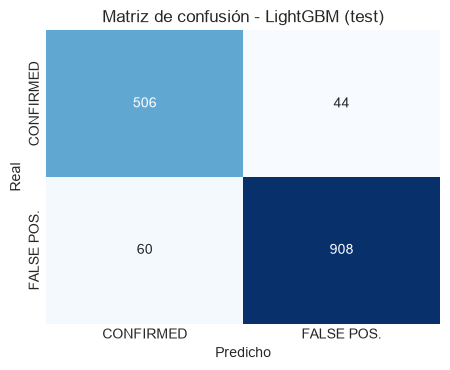

In [18]:
cm = confusion_matrix(y_test, y_pred, labels=[1, 0])   # filas/columnas: CONFIRMED, FALSE POSITIVE
tp, fn, fp, tn = cm.ravel()
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}  (total={cm.sum()})")

fig, ax = plt.subplots(figsize=(4.6, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['CONFIRMED', 'FALSE POS.'], yticklabels=['CONFIRMED', 'FALSE POS.'], ax=ax)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title(f'Matriz de confusión - {best_model_name} (test)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_confusion.png', dpi=150)
plt.show()

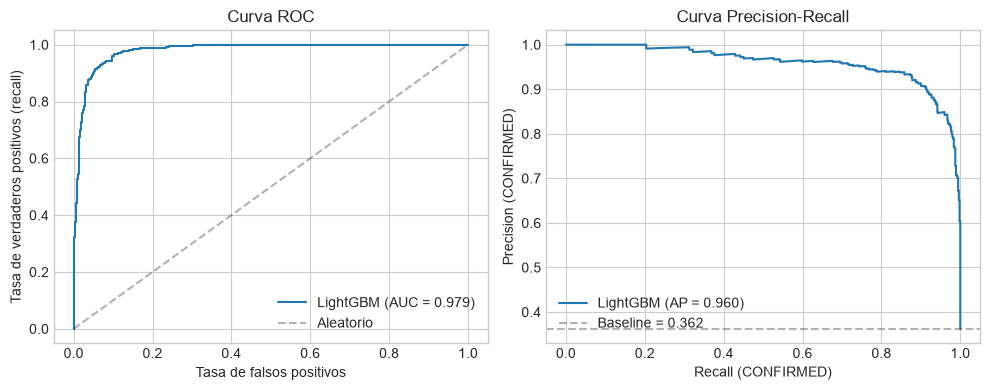

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, label=f"{best_model_name} (AUC = {ci['roc_auc'][0]:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aleatorio')
axes[0].set_xlabel('Tasa de falsos positivos'); axes[0].set_ylabel('Tasa de verdaderos positivos (recall)')
axes[0].set_title('Curva ROC'); axes[0].legend(loc='lower right')

prec, rec, _ = precision_recall_curve(y_test, y_proba)
axes[1].plot(rec, prec, label=f"{best_model_name} (AP = {ci['pr_auc'][0]:.3f})")
axes[1].axhline(y_test.mean(), color='k', ls='--', alpha=0.3, label=f"Baseline = {y_test.mean():.3f}")
axes[1].set_xlabel('Recall (CONFIRMED)'); axes[1].set_ylabel('Precision (CONFIRMED)')
axes[1].set_title('Curva Precision-Recall'); axes[1].legend(loc='lower left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_roc_pr.png', dpi=150)
plt.show()

In [20]:
# ¿Es real la diferencia entre XGBoost y LightGBM? Bootstrap pareado sobre el test
p_xgb = grid_xgb.best_estimator_.predict_proba(X_test)[:, 1]
p_lgbm = grid_lgbm.best_estimator_.predict_proba(X_test)[:, 1]
diff_models = paired_diff_ci(p_lgbm, p_xgb)
print(f"ROC-AUC test  XGBoost: {roc_auc_score(y_test, p_xgb):.4f} | LightGBM: {roc_auc_score(y_test, p_lgbm):.4f}")
print(f"Diferencia LightGBM - XGBoost: {diff_models[0]:+.4f}  IC95 [{diff_models[1]:+.4f}, {diff_models[2]:+.4f}]")

ROC-AUC test  XGBoost: 0.9796 | LightGBM: 0.9792
Diferencia LightGBM - XGBoost: -0.0004  IC95 [-0.0019, +0.0012]


## 9. Interpretabilidad: importancia de variables

In [21]:
def gain_importance(pipe):
    # Importancia por ganancia (gain) normalizada, con nombres de las variables seleccionadas
    pre = pipe.named_steps['preprocessor']
    names = [f.split('__', 1)[1] for f in pre.get_feature_names_out()]     # quitar prefijo num__/cat__
    names = [names[i] for i in pipe.named_steps['select'].get_support(indices=True)]
    m = pipe.named_steps['model']
    if hasattr(m, 'booster_'):                                             # LightGBM
        g = m.booster_.feature_importance(importance_type='gain').astype(float)
    else:                                                                  # XGBoost
        s = m.get_booster().get_score(importance_type='gain')
        g = np.array([s.get(f'f{i}', 0.0) for i in range(len(names))])
    return (pd.DataFrame({'feature': names, 'importance': g / g.sum()})
            .sort_values('importance', ascending=False).reset_index(drop=True))

feat_imp = gain_importance(best_pipe)
print(f"Variables usadas por el modelo final: {len(feat_imp)}")
feat_imp.head(12)

Variables usadas por el modelo final: 19


,feature,importance
0,koi_prad,0.202109
1,koi_model_snr,0.132609
2,koi_period,0.119003
3,koi_duration,0.084181
4,koi_impact,0.081947
5,koi_depth,0.055191
6,koi_insol,0.048296
7,koi_tce_delivname_q1_q17_dr25_tce,0.041614
8,koi_steff,0.036385
9,koi_teq,0.030856


## 10. Experimentos de *data leakage*

Se reentrenan modelos con los **mismos hiperparámetros** del modelo final, pero agregando las columnas excluidas, y se comparan en test con bootstrap pareado:
1. **+ columnas `_err`** (leakage sutil).
2. **+ `koi_score` y banderas `koi_fpflag_*`** (leakage explícito).

In [22]:
def variant(extra_cols):
    # Mismo modelo final, con columnas adicionales tomadas de df
    Xv = X.join(df[extra_cols])
    pipe = make_pipeline(clone(best_pipe.named_steps['model']), k=best_pipe.named_steps['select'].k,
                         pre=make_preprocessor(numeric_cols + extra_cols))
    pipe.fit(Xv.loc[X_train.index], y_train)
    return pipe, pipe.predict_proba(Xv.loc[X_test.index])[:, 1]

# 1) Con columnas de incertidumbre
err_pipe, p_err = variant(err_cols)
ci_err = bootstrap_ci(p_err)
diff_err = paired_diff_ci(p_err, y_proba)
imp_err = gain_importance(err_pipe)
print(f"Columnas _err agregadas: {len(err_cols)}")
print(f"ROC-AUC test  final (sin _err): {ci['roc_auc'][0]:.4f} | con _err: {ci_err['roc_auc'][0]:.4f}")
print(f"Diferencia (con _err - sin _err): {diff_err[0]:+.4f}  IC95 [{diff_err[1]:+.4f}, {diff_err[2]:+.4f}]")
print(f"F1 con _err: {ci_err['f1_confirmed'][0]:.3f}")
print("Top variables del modelo con _err:")
print(imp_err.head(6).to_string(index=False))

# 2) Con variables del vetting
_, p_leak = variant(leak_cols)
auc_leak = roc_auc_score(y_test, p_leak)
ks = df.loc[X_test.index, 'koi_score']
auc_score_only = roc_auc_score(y_test[ks.notna()], ks[ks.notna()])
print(f"\nROC-AUC test con koi_score + koi_fpflag_*: {auc_leak:.4f}")
print(f"ROC-AUC usando solo koi_score (sin modelo): {auc_score_only:.4f}")

Columnas _err agregadas: 20
ROC-AUC test  final (sin _err): 0.9792 | con _err: 0.9870
Diferencia (con _err - sin _err): +0.0078  IC95 [+0.0045, +0.0113]
F1 con _err: 0.925
Top variables del modelo con _err:
          feature  importance
   koi_steff_err1    0.177064
         koi_prad    0.152019
       koi_period    0.068985
   koi_steff_err2    0.066147
koi_duration_err1    0.059882
koi_duration_err2    0.049138



ROC-AUC test con koi_score + koi_fpflag_*: 1.0000
ROC-AUC usando solo koi_score (sin modelo): 0.9811


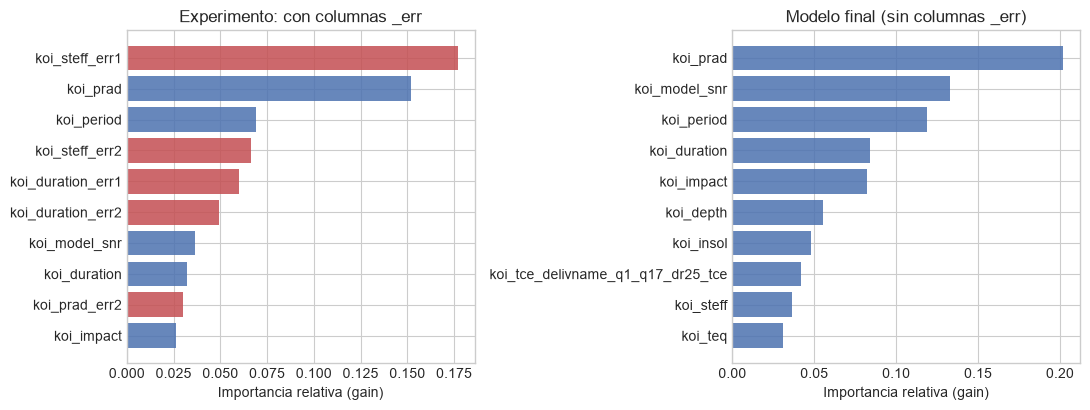

In [23]:
# Figura comparativa de importancias: modelo con columnas _err vs modelo final
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, data, title in [(axes[0], imp_err, 'Experimento: con columnas _err'),
                        (axes[1], feat_imp, 'Modelo final (sin columnas _err)')]:
    t = data.head(10).iloc[::-1]
    colors = ['#c44e52' if f.endswith(('_err1', '_err2')) else '#4c72b0' for f in t['feature']]
    ax.barh(t['feature'], t['importance'], color=colors, alpha=0.85)
    ax.set_title(title); ax.set_xlabel('Importancia relativa (gain)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_importance_compare.png', dpi=150)
plt.show()

## 11. Análisis de errores y sesgos

In [24]:
test_df = X_test.copy()
test_df['y_true'] = y_test.values
test_df['y_pred'] = y_pred
test_df['p_conf'] = y_proba

groups = {
    'TP (planeta detectado)': (test_df.y_true == 1) & (test_df.y_pred == 1),
    'FN (planeta perdido)':   (test_df.y_true == 1) & (test_df.y_pred == 0),
    'FP (falsa alarma)':      (test_df.y_true == 0) & (test_df.y_pred == 1),
    'TN (FP descartado)':     (test_df.y_true == 0) & (test_df.y_pred == 0),
}
vars_ = ['koi_period', 'koi_depth', 'koi_prad', 'koi_model_snr', 'koi_kepmag', 'p_conf']
err_table = pd.DataFrame({g: test_df.loc[m, vars_].median() for g, m in groups.items()}).T
err_table.insert(0, 'n', [m.sum() for m in groups.values()])
err_table.round(3)

,n,koi_period,koi_depth,koi_prad,koi_model_snr,koi_kepmag,p_conf
TP (planeta detectado),506,12.001,511.15,2.21,31.60,14.604,0.996
FN (planeta perdido),44,6.567,290.35,1.67,21.25,14.482,0.159
FP (falsa alarma),60,8.480,336.30,1.75,19.65,14.589,0.892
TN (FP descartado),908,4.637,641.10,16.37,37.70,14.288,0.000


In [25]:
# Recall de planetas por rango de brillo (Kp mayor = estrella más tenue) y por SNR del tránsito
test_df['kp_bin'] = pd.cut(test_df['koi_kepmag'], bins=[0, 13, 14, 15, 20], labels=['Kp<13', '13-14', '14-15', 'Kp>15'])
test_df['snr_bin'] = pd.cut(test_df['koi_model_snr'], bins=[0, 10, 20, 50, 1e9], labels=['<10', '10-20', '20-50', '>50'])
conf = test_df[test_df.y_true == 1]
recall_by = lambda col: conf.groupby(col, observed=False).apply(
    lambda d: pd.Series({'n_planetas': len(d), 'recall': (d.y_pred == 1).mean()}))
recall_by_kp, recall_by_snr = recall_by('kp_bin'), recall_by('snr_bin')
print("Recall por magnitud Kepler:\n", recall_by_kp.round(3))
print("\nRecall por SNR del tránsito:\n", recall_by_snr.round(3))

Recall por magnitud Kepler:
         n_planetas  recall
kp_bin                    
Kp<13         76.0   0.921
13-14        112.0   0.911
14-15        166.0   0.934
Kp>15        196.0   0.913

Recall por SNR del tránsito:
          n_planetas  recall
snr_bin                    
<10             9.0   0.444
10-20         142.0   0.887
20-50         257.0   0.949
>50           142.0   0.930


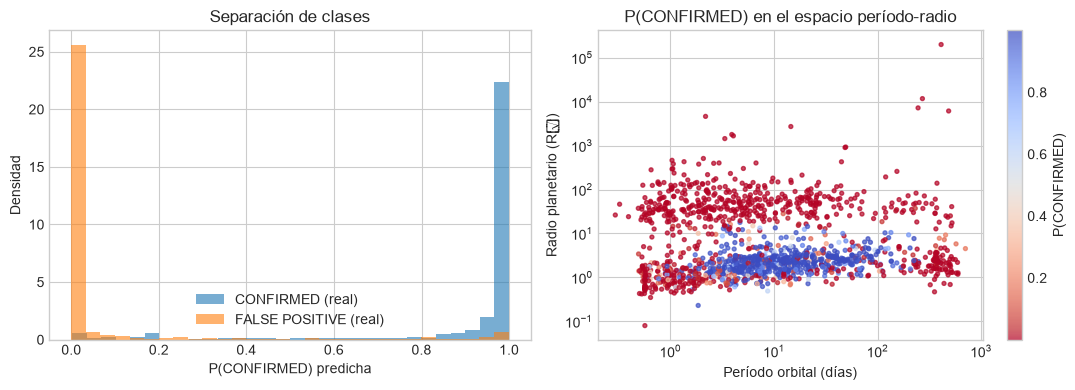

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(test_df.loc[test_df.y_true == 1, 'p_conf'], bins=30, alpha=0.6, density=True, label='CONFIRMED (real)')
axes[0].hist(test_df.loc[test_df.y_true == 0, 'p_conf'], bins=30, alpha=0.6, density=True, label='FALSE POSITIVE (real)')
axes[0].set_xlabel('P(CONFIRMED) predicha'); axes[0].set_ylabel('Densidad')
axes[0].set_title('Separación de clases'); axes[0].legend()

sc = axes[1].scatter(test_df['koi_period'], test_df['koi_prad'], c=test_df['p_conf'], cmap='coolwarm_r', s=8, alpha=0.7)
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('Período orbital (días)'); axes[1].set_ylabel('Radio planetario (R⊕)')
axes[1].set_title('P(CONFIRMED) en el espacio período-radio')
plt.colorbar(sc, ax=axes[1], label='P(CONFIRMED)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_errors.png', dpi=150)
plt.show()

## 12. Curvas de aprendizaje

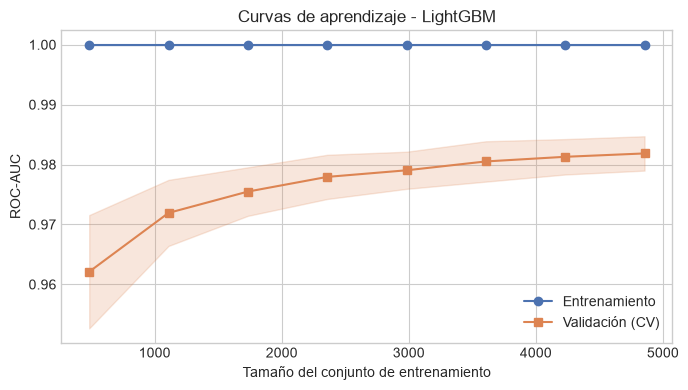

{'train_final': 1.0, 'val_final': 0.9818487801266256, 'gap': 0.018151219873374425}


In [27]:
train_sizes, train_scores, val_scores = learning_curve(
    clone(best_pipe), X_train, y_train, cv=cv, scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, shuffle=True, random_state=SEED)
tr_m, tr_s = train_scores.mean(1), train_scores.std(1)
va_m, va_s = val_scores.mean(1), val_scores.std(1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(train_sizes, tr_m, 'o-', label='Entrenamiento', color='#4c72b0')
ax.fill_between(train_sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.2, color='#4c72b0')
ax.plot(train_sizes, va_m, 's-', label='Validación (CV)', color='#dd8452')
ax.fill_between(train_sizes, va_m - va_s, va_m + va_s, alpha=0.2, color='#dd8452')
ax.set_xlabel('Tamaño del conjunto de entrenamiento'); ax.set_ylabel('ROC-AUC')
ax.set_title(f'Curvas de aprendizaje - {best_model_name}'); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_learning.png', dpi=150)
plt.show()
lc = {'train_final': float(tr_m[-1]), 'val_final': float(va_m[-1]), 'gap': float(tr_m[-1] - va_m[-1])}
print(lc)

## 13. Uso operativo: priorización de candidatos y ahorro de tiempo de telescopio

Se aplica al test el umbral elegido en la sección 7 (sin haber mirado el test) y se mide qué recall de planetas y qué fracción de KOIs a observar resultan, con IC 95 % por bootstrap.

In [28]:
flag_test = (y_proba >= THR95)
op_point = {
    'recall': recall_score(y_test, flag_test), 'precision': precision_score(y_test, flag_test),
    'flag_rate': flag_test.mean(),
}
boot_op = pd.DataFrame([{'recall': recall_score(y_test_arr[i], flag_test[i]),
                         'precision': precision_score(y_test_arr[i], flag_test[i]),
                         'flag_rate': flag_test[i].mean()} for i in boot_idx])
op_ci = {k: (float(op_point[k]), float(boot_op[k].quantile(0.025)), float(boot_op[k].quantile(0.975))) for k in op_point}
for k, (v, lo, hi) in op_ci.items():
    print(f"{k:10s} test: {v:.3f}  IC95 [{lo:.3f}, {hi:.3f}]")
print(f"Ahorro de observaciones frente a observar todos: {1 - op_point['flag_rate']:.1%}")

recall     test: 0.940  IC95 [0.919, 0.959]
precision  test: 0.867  IC95 [0.838, 0.893]
flag_rate  test: 0.393  IC95 [0.369, 0.418]
Ahorro de observaciones frente a observar todos: 60.7%


In [29]:
candidates = df_raw[df_raw['koi_disposition'] == 'CANDIDATE'].copy()
candidates['p_confirmed'] = best_pipe.predict_proba(candidates[X.columns])[:, 1]

n_cand = len(candidates)
n_090 = int((candidates.p_confirmed > 0.90).sum())
n_098 = int((candidates.p_confirmed > 0.98).sum())
n_thr = int((candidates.p_confirmed >= THR95).sum())
print(f"Candidatos: {n_cand} | P>0.90: {n_090} | P>0.98: {n_098} | sobre el umbral operativo: {n_thr}")
candidates.nlargest(10, 'p_confirmed')[['kepoi_name', 'koi_period', 'koi_prad', 'koi_insol', 'koi_steff', 'p_confirmed']]

Candidatos: 1977 | P>0.90: 387 | P>0.98: 200 | sobre el umbral operativo: 747


,kepoi_name,koi_period,koi_prad,koi_insol,koi_steff,p_confirmed
1346,K00935.04,9.617314,1.94,246.13,6035.0,0.999746
3059,K02220.04,7.664629,1.60,353.31,5640.0,0.999662
5153,K04032.05,7.235242,0.82,191.14,5574.0,0.999618
2553,K01861.01,17.504417,3.56,108.78,5815.0,0.999581
2544,K01856.01,46.299105,4.33,29.04,5396.0,0.999493
1502,K01053.02,46.245164,2.46,17.15,5553.0,0.999407
1623,K01145.01,30.587215,2.32,35.08,5944.0,0.999401
6011,K04811.01,21.743414,2.23,96.15,5767.0,0.999385
245,K00211.01,124.035899,11.13,6.88,5822.0,0.999367
3966,K02963.02,7.351013,1.42,303.08,5951.0,0.999292


## 14. Guardar modelo y resultados

In [30]:
import joblib
joblib.dump(best_pipe, 'exoplanet_classifier_pipeline.pkl')

py = lambda v: v.item() if hasattr(v, 'item') else v          # numpy -> tipos nativos para JSON
ci_json = lambda d: {k: [round(float(x), 4) for x in v] for k, v in d.items()}

results = {
    'n_raw': int(len(df_raw)),
    'class_counts_raw': df_raw['koi_disposition'].value_counts().to_dict(),
    'n_binary': int(len(df)), 'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
    'test_counts': {'confirmed': int(y_test.sum()), 'false_positive': int((y_test == 0).sum())},
    'dropped_cols': cols_to_drop, 'n_err_cols_dropped': len(err_cols_all),
    'n_numeric': len(numeric_cols), 'n_categorical': len(categorical_cols),
    'numeric_cols': numeric_cols, 'n_features_selected': len(feat_imp),
    'steff_err1_median_by_class': df.groupby('koi_disposition')['koi_steff_err1'].median().to_dict(),
    'cv_table': {k: {'mean': round(float(r['mean']), 4), 'std': round(float(r['std']), 4)} for k, r in cv_table.iterrows()},
    'best_model': best_model_name,
    'best_params': {k: py(v) for k, v in best_grid.best_params_.items()},
    'best_cv_xgb': round(float(grid_xgb.best_score_), 4), 'best_params_xgb': {k: py(v) for k, v in grid_xgb.best_params_.items()},
    'best_cv_lgbm': round(float(grid_lgbm.best_score_), 4), 'best_params_lgbm': {k: py(v) for k, v in grid_lgbm.best_params_.items()},
    'test_metrics_ci': ci_json(ci), 'pr_baseline': round(float(y_test.mean()), 4),
    'confusion': {'tp': int(tp), 'fn': int(fn), 'fp': int(fp), 'tn': int(tn)},
    'test_auc_xgb': round(float(roc_auc_score(y_test, p_xgb)), 4), 'test_auc_lgbm': round(float(roc_auc_score(y_test, p_lgbm)), 4),
    'diff_lgbm_minus_xgb': [round(x, 4) for x in diff_models],
    'feature_importance_top12': feat_imp.head(12).round(4).to_dict('records'),
    'with_err': {'n_err_cols': len(err_cols), 'metrics_ci': ci_json(ci_err),
                 'diff_with_minus_without': [round(x, 4) for x in diff_err],
                 'importance_top10': imp_err.head(10).round(4).to_dict('records')},
    'leakage': {'auc_with_vetting': round(float(auc_leak), 5), 'auc_koi_score_only': round(float(auc_score_only), 4)},
    'error_table': err_table.round(3).reset_index().rename(columns={'index': 'group'}).to_dict('records'),
    'recall_by_kp': recall_by_kp.round(3).reset_index().astype({'kp_bin': str}).to_dict('records'),
    'recall_by_snr': recall_by_snr.round(3).reset_index().astype({'snr_bin': str}).to_dict('records'),
    'learning_curve': {k: round(v, 4) for k, v in lc.items()},
    'threshold_oof': {'thr': round(THR95, 4), 'oof_recall': round(float(rec_o[idx_o]), 4),
                      'oof_precision': round(float(prec_o[idx_o]), 4),
                      'oof_flag_rate': round(float((oof_proba >= THR95).mean()), 4),
                      'oof_auc': round(float(roc_auc_score(y_train, oof_proba)), 4)},
    'operational_test_ci': {k: [round(x, 4) for x in v] for k, v in op_ci.items()},
    'candidates': {'n': n_cand, 'p090': n_090, 'p098': n_098, 'over_thr': n_thr},
}
with open('results.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Guardados: exoplanet_classifier_pipeline.pkl, results.json, figuras en ./figures")

Guardados: exoplanet_classifier_pipeline.pkl, results.json, figuras en ./figures



## 15. Conclusiones

### Resultados del modelo final (test hold-out, n = 1,518; IC 95 % por bootstrap)
- **Modelo final**: LightGBM sin columnas de incertidumbre (400 árboles, `num_leaves=63`, `learning_rate=0.03`, `subsample=0.8`, 19 variables), elegido por GridSearchCV con 5 *folds* (ROC-AUC CV = 0.982).
- **ROC-AUC = 0.979 [0.973, 0.985]**, **PR-AUC = 0.960 [0.945, 0.972]** (baseline 0.362), **F1 = 0.907 [0.887, 0.924]**, precision = 0.894 y recall = 0.920.
- Matriz de confusión: TP = 506, FN = 44, FP = 60, TN = 908.
- XGBoost y LightGBM son **estadísticamente indistinguibles**: la diferencia de AUC en test es −0.0004 [−0.0019, +0.0012].

### Hallazgos clave
1. **Leakage explícito**: con `koi_score` y `koi_fpflag_*` el ROC-AUC llega a 1.000, porque esas columnas reproducen la decisión del catálogo.
2. **Leakage sutil**: agregar las 20 columnas `_err` sube el AUC en **+0.008 [+0.005, +0.011]**. La diferencia es real, pero proviene de que las incertidumbres reflejan el proceso de confirmación (mediana de `koi_steff_err1`: 108 K en confirmados frente a 165 K en falsos positivos), así que se excluyen. Sin ellas, el ranking de variables es físico: radio planetario, SNR, período, duración e impacto.
3. **Los errores se concentran en señales débiles y planetas pequeños** (recall de 0.89 con SNR entre 10 y 20 y de 0.44 con SNR < 10). La magnitud estelar casi no influye (recall de 0.91 a 0.93 en todos los rangos).
4. **Ligero sobreajuste**: AUC de entrenamiento = 1.00 frente a 0.982 en validación. La curva de validación sigue subiendo con más datos.

### Uso operativo (umbral elegido sin mirar el test)
- El umbral P ≥ 0.309 se eligió con predicciones *out-of-fold* del entrenamiento para alcanzar un recall del 95 %.
- En test recupera el **94.0 % [91.9, 95.9]** de los planetas observando solo el **39.3 % [36.9, 41.8]** de los KOIs, lo que supone un **ahorro aproximado del 61 %**.
- De los 1,977 `CANDIDATE`, 387 tienen P > 0.90 y 200 superan 0.98.

### Mejoras futuras
Calibrar probabilidades (isotónica), explicar cada candidato con SHAP, entrenar con curvas de luz crudas (CNN 1D) para mejorar en baja SNR y hacer *domain adaptation* hacia TESS.
